In [1]:
import sys

print("Python Environment:")
print(sys.executable)

Python Environment:
c:\Users\itsab\OneDrive\Desktop\Kutch-ET0-NASA-POWER-GEE-Analysis\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")
print("Kutch ET0 Analysis Started.")

All libraries imported successfully!
Kutch ET0 Analysis Started.


In [3]:
from pathlib import Path

ROOT = Path.cwd()

if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project Root:", ROOT)
print("Data Folder:", DATA_DIR)
print("Results Folder:", RESULTS_DIR)

Project Root: c:\Users\itsab\OneDrive\Desktop\Kutch-ET0-NASA-POWER-GEE-Analysis
Data Folder: c:\Users\itsab\OneDrive\Desktop\Kutch-ET0-NASA-POWER-GEE-Analysis\data
Results Folder: c:\Users\itsab\OneDrive\Desktop\Kutch-ET0-NASA-POWER-GEE-Analysis\results


In [4]:
nasa = pd.read_csv(DATA_DIR / "nasa_power_data.csv")
gee = pd.read_csv(DATA_DIR / "gee_data.csv")

print("NASA POWER Dataset Shape:", nasa.shape)
print("GEE Dataset Shape:", gee.shape)

NASA POWER Dataset Shape: (106423, 16)
GEE Dataset Shape: (139513, 12)


In [5]:
print("NASA POWER Columns:")
print(nasa.columns.tolist())

print("\nGEE Columns:")
print(gee.columns.tolist())

print("\nNASA POWER First 5 Rows:")
display(nasa.head())

print("\nGEE First 5 Rows:")
display(gee.head())

NASA POWER Columns:
['YEAR', 'MO', 'DY', 'HR', 'Rs', 'Temp', 'RH', 'Wind', 'WD10M', 'u2', 'es', 'ea', 'delta', 'Rn', 'G', 'ET0']

GEE Columns:
['date', 'T', 'RH', 'u2', 'es', 'ea', 'Delta', 'Rn', 'ET0', 'hour', 'factor', 'ET0_hourly']

NASA POWER First 5 Rows:


,YEAR,MO,DY,HR,Rs,Temp,RH,Wind,WD10M,u2,es,ea,delta,Rn,G,ET0
0,2010,1,1,0,0.0,15.36,33.91,3.19,26.2,2.38612,1.745275,0.591823,0.112037,0.0,0.0,0.100646
1,2010,1,1,1,0.0,14.80,35.33,3.31,28.1,2.47588,1.683512,0.594785,0.108553,0.0,0.0,0.099395
2,2010,1,1,2,0.0,14.30,36.48,3.37,31.3,2.52076,1.629994,0.594622,0.105520,0.0,0.0,0.097261
3,2010,1,1,3,0.0,13.86,37.53,3.39,35.3,2.53572,1.584139,0.594527,0.102912,0.0,0.0,0.094600
4,2010,1,1,4,0.0,13.42,38.52,3.40,41.1,2.54320,1.539420,0.592985,0.100358,0.0,0.0,0.091850



GEE First 5 Rows:


,date,T,RH,u2,es,ea,Delta,Rn,ET0,hour,factor,ET0_hourly
0,2010-01-01 00:00:00,20.470684,43.419683,2.856465,2.407285,1.045236,0.148468,15,6.0887,0,0.02,0.121774
1,2010-01-01 01:00:00,20.470684,43.419683,2.856465,2.407285,1.045236,0.148468,15,6.0887,1,0.02,0.121774
2,2010-01-01 02:00:00,20.470684,43.419683,2.856465,2.407285,1.045236,0.148468,15,6.0887,2,0.02,0.121774
3,2010-01-01 03:00:00,20.470684,43.419683,2.856465,2.407285,1.045236,0.148468,15,6.0887,3,0.02,0.121774
4,2010-01-01 04:00:00,20.470684,43.419683,2.856465,2.407285,1.045236,0.148468,15,6.0887,4,0.02,0.121774


In [6]:
print("NASA POWER Missing Values:")
display(nasa.isnull().sum())

print("\nGEE Missing Values:")
display(gee.isnull().sum())

print("\nNASA POWER Data Types:")
print(nasa.dtypes)

print("\nGEE Data Types:")
print(gee.dtypes)


NASA POWER Missing Values:


YEAR     0
MO       0
DY       0
HR       0
Rs       0
Temp     1
RH       1
Wind     1
WD10M    1
u2       1
es       1
ea       1
delta    1
Rn       0
G        0
ET0      1
dtype: int64


GEE Missing Values:


date          0
T             0
RH            0
u2            0
es            0
ea            0
Delta         0
Rn            0
ET0           0
hour          0
factor        0
ET0_hourly    0
dtype: int64


NASA POWER Data Types:
YEAR       int64
MO         int64
DY         int64
HR         int64
Rs       float64
Temp     float64
RH       float64
Wind     float64
WD10M    float64
u2       float64
es       float64
ea       float64
delta    float64
Rn       float64
G        float64
ET0      float64
dtype: object

GEE Data Types:
date              str
T             float64
RH            float64
u2            float64
es            float64
ea            float64
Delta         float64
Rn              int64
ET0           float64
hour            int64
factor        float64
ET0_hourly    float64
dtype: object


In [7]:
# Check duplicate records

print("NASA POWER Duplicate Rows:", nasa.duplicated().sum())
print("GEE Duplicate Rows:", gee.duplicated().sum())

NASA POWER Duplicate Rows: 0
GEE Duplicate Rows: 0


In [8]:
print("NASA POWER Dataset Summary")
display(nasa.describe(include="all"))

print("\nGEE Dataset Summary")
display(gee.describe(include="all"))

NASA POWER Dataset Summary


,YEAR,MO,DY,HR,Rs,Temp,RH,Wind,WD10M,u2,es,ea,delta,Rn,G,ET0
count,106423.000000,106423.000000,106423.000000,106423.000000,106423.000000,106422.000000,106422.000000,106422.000000,106422.000000,106422.000000,106422.000000,106422.000000,106422.000000,106423.000000,106423.000000,106422.000000
mean,2015.575524,6.463622,15.708287,11.499441,0.807182,27.015732,52.237188,4.422761,200.163227,3.308225,3.851695,1.866944,0.221460,0.621530,0.062153,0.281465
std,3.501609,3.472669,8.796650,6.922354,1.071107,7.308094,27.025557,2.164356,102.339280,1.618938,1.582024,0.974624,0.079391,0.824752,0.082475,0.277721
min,2010.000000,1.000000,1.000000,0.000000,0.000000,2.990000,1.920000,0.030000,0.000000,0.022440,0.757229,0.099233,0.053744,0.000000,0.000000,0.000000
25%,2013.000000,3.000000,8.000000,5.000000,0.000000,22.600000,27.770000,2.880000,86.800000,2.154240,2.742181,0.930327,0.166363,0.000000,0.000000,0.063873
50%,2016.000000,6.000000,16.000000,11.000000,0.030000,27.420000,51.215000,3.980000,240.700000,2.977040,3.654139,1.910652,0.213690,0.023100,0.002310,0.150327
75%,2019.000000,9.000000,23.000000,17.000000,1.650000,31.920000,76.130000,5.710000,264.900000,4.271080,4.733323,2.791888,0.267623,1.270500,0.127050,0.483435
max,2022.000000,12.000000,31.000000,23.000000,3.780000,46.890000,100.000000,16.430000,359.900000,12.289640,10.553761,3.810668,0.535503,2.910600,0.291060,1.355117



GEE Dataset Summary


,date,T,RH,u2,es,ea,Delta,Rn,ET0,hour,factor,ET0_hourly
count,139513,139513.000000,139513.000000,139513.000000,139513.000000,139513.000000,139513.000000,139513.0,139513.000000,139513.000000,139513.000000,139513.000000
unique,139513,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2010-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,26.970712,55.053402,4.181026,3.643989,2.049318,0.212514,15.0,6.898138,11.499918,0.041674,0.287462
std,NaN,4.056352,15.201722,1.369696,0.802996,0.797915,0.041278,0.0,1.294770,6.922255,0.020095,0.150636
min,NaN,18.079167,31.250780,1.972213,2.074286,0.830205,0.130338,15.0,4.732711,0.000000,0.020000,0.094654
25%,NaN,24.001662,42.637969,3.093811,2.984215,1.262023,0.179109,15.0,5.906330,5.000000,0.020000,0.135637
50%,NaN,28.049568,50.940666,3.666577,3.790854,1.968638,0.220634,15.0,6.649548,11.000000,0.060000,0.309447
75%,NaN,30.023686,67.590124,5.344036,4.248833,2.882639,0.243650,15.0,8.011513,17.000000,0.060000,0.406567


In [9]:
print("NASA POWER Columns:")
print(nasa.columns.tolist())

print("\nGEE Columns:")
print(gee.columns.tolist())

NASA POWER Columns:
['YEAR', 'MO', 'DY', 'HR', 'Rs', 'Temp', 'RH', 'Wind', 'WD10M', 'u2', 'es', 'ea', 'delta', 'Rn', 'G', 'ET0']

GEE Columns:
['date', 'T', 'RH', 'u2', 'es', 'ea', 'Delta', 'Rn', 'ET0', 'hour', 'factor', 'ET0_hourly']


In [10]:
print("NASA POWER Dataset:")
print(nasa.columns.tolist())
print(nasa.head(3))

print("\nGEE Dataset:")
print(gee.columns.tolist())
print(gee.head(3))

NASA POWER Dataset:
['YEAR', 'MO', 'DY', 'HR', 'Rs', 'Temp', 'RH', 'Wind', 'WD10M', 'u2', 'es', 'ea', 'delta', 'Rn', 'G', 'ET0']
   YEAR  MO  DY  HR   Rs   Temp     RH  Wind  WD10M       u2        es  \
0  2010   1   1   0  0.0  15.36  33.91  3.19   26.2  2.38612  1.745275   
1  2010   1   1   1  0.0  14.80  35.33  3.31   28.1  2.47588  1.683512   
2  2010   1   1   2  0.0  14.30  36.48  3.37   31.3  2.52076  1.629994   

         ea     delta   Rn    G       ET0  
0  0.591823  0.112037  0.0  0.0  0.100646  
1  0.594785  0.108553  0.0  0.0  0.099395  
2  0.594622  0.105520  0.0  0.0  0.097261  

GEE Dataset:
['date', 'T', 'RH', 'u2', 'es', 'ea', 'Delta', 'Rn', 'ET0', 'hour', 'factor', 'ET0_hourly']
                  date          T         RH        u2        es        ea  \
0  2010-01-01 00:00:00  20.470684  43.419683  2.856465  2.407285  1.045236   
1  2010-01-01 01:00:00  20.470684  43.419683  2.856465  2.407285  1.045236   
2  2010-01-01 02:00:00  20.470684  43.419683  2.856465  2.

In [11]:
# NASA POWER: Create datetime column

nasa["datetime"] = pd.to_datetime(
    nasa[["YEAR", "MO", "DY", "HR"]].rename(
        columns={
            "YEAR": "year",
            "MO": "month",
            "DY": "day",
            "HR": "hour"
        }
    )
)

# GEE: Convert date column to datetime

gee["datetime"] = pd.to_datetime(gee["date"])

print("NASA POWER DateTime:")
display(nasa[["datetime", "ET0"]].head())

print("\nGEE DateTime:")
display(gee[["datetime", "ET0", "ET0_hourly"]].head())

print("\nDate conversion completed successfully!")

NASA POWER DateTime:


,datetime,ET0
0,2010-01-01 00:00:00,0.100646
1,2010-01-01 01:00:00,0.099395
2,2010-01-01 02:00:00,0.097261
3,2010-01-01 03:00:00,0.094600
4,2010-01-01 04:00:00,0.091850



GEE DateTime:


,datetime,ET0,ET0_hourly
0,2010-01-01 00:00:00,6.0887,0.121774
1,2010-01-01 01:00:00,6.0887,0.121774
2,2010-01-01 02:00:00,6.0887,0.121774
3,2010-01-01 03:00:00,6.0887,0.121774
4,2010-01-01 04:00:00,6.0887,0.121774



Date conversion completed successfully!


In [12]:
print("NASA POWER Date Range:")
print("Start:", nasa["datetime"].min())
print("End:", nasa["datetime"].max())

print("\nGEE Date Range:")
print("Start:", gee["datetime"].min())
print("End:", gee["datetime"].max())

NASA POWER Date Range:
Start: 2010-01-01 00:00:00
End: 2022-02-21 06:00:00

GEE Date Range:
Start: 2010-01-01 00:00:00
End: 2025-12-01 00:00:00


In [13]:
print("NASA POWER Missing Values:")
display(nasa.isnull().sum())

print("\nGEE Missing Values:")
display(gee.isnull().sum())

NASA POWER Missing Values:


YEAR        0
MO          0
DY          0
HR          0
Rs          0
Temp        1
RH          1
Wind        1
WD10M       1
u2          1
es          1
ea          1
delta       1
Rn          0
G           0
ET0         1
datetime    0
dtype: int64


GEE Missing Values:


date          0
T             0
RH            0
u2            0
es            0
ea            0
Delta         0
Rn            0
ET0           0
hour          0
factor        0
ET0_hourly    0
datetime      0
dtype: int64

In [14]:
# Extract date from datetime

nasa["date_only"] = nasa["datetime"].dt.date
gee["date_only"] = gee["datetime"].dt.date

# Count hourly records per day

nasa_daily_counts = nasa.groupby("date_only").size()
gee_daily_counts = gee.groupby("date_only").size()

print("NASA POWER Hourly Records Per Day:")
print(nasa_daily_counts.describe())

print("\nGEE Hourly Records Per Day:")
print(gee_daily_counts.describe())

print("\nNASA POWER Incomplete Days:")
display(nasa_daily_counts[nasa_daily_counts != 24].head(10))

print("\nGEE Incomplete Days:")
display(gee_daily_counts[gee_daily_counts != 24].head(10))

NASA POWER Hourly Records Per Day:
count    4435.000000
mean       23.996167
std         0.255271
min         7.000000
25%        24.000000
50%        24.000000
75%        24.000000
max        24.000000
dtype: float64

GEE Hourly Records Per Day:
count    5814.000000
mean       23.996044
std         0.301641
min         1.000000
25%        24.000000
50%        24.000000
75%        24.000000
max        24.000000
dtype: float64

NASA POWER Incomplete Days:


date_only
2022-02-21    7
dtype: int64


GEE Incomplete Days:


date_only
2025-12-01    1
dtype: int64

In [15]:
gee_et0_variation = gee.groupby("date_only")["ET0"].nunique()

print("Days with inconsistent GEE ET0 values:")
print((gee_et0_variation > 1).sum())

print("\nUnique daily ET0 values per day:")
display(gee_et0_variation.value_counts())

Days with inconsistent GEE ET0 values:
0

Unique daily ET0 values per day:


ET0
1    5814
Name: count, dtype: int64

In [16]:
nasa_dates = set(nasa["date_only"].unique())
gee_dates = set(gee["date_only"].unique())

common_dates = sorted(nasa_dates.intersection(gee_dates))

print("NASA POWER Unique Dates:", len(nasa_dates))
print("GEE Unique Dates:", len(gee_dates))
print("Common Dates:", len(common_dates))

print("Common Period Start:", common_dates[0])
print("Common Period End:", common_dates[-1])

NASA POWER Unique Dates: 4435
GEE Unique Dates: 5814
Common Dates: 4435
Common Period Start: 2010-01-01
Common Period End: 2022-02-21


In [17]:
# Count valid hourly ET0 observations per day

nasa_daily = nasa.groupby("date_only").agg(
    NASA_ET0=("ET0", lambda x: x.sum(min_count=24)),
    valid_hours=("ET0", "count"),
    unique_hours=("HR", "nunique")
).reset_index()

# Keep only complete days with 24 valid hourly records

nasa_daily = nasa_daily[
    (nasa_daily["valid_hours"] == 24) &
    (nasa_daily["unique_hours"] == 24)
].copy()

print("NASA POWER Daily Dataset:", nasa_daily.shape)
print("\nFirst 5 Daily Records:")
display(nasa_daily.head())

print("\nLast 5 Daily Records:")
display(nasa_daily.tail())

NASA POWER Daily Dataset: (4434, 4)

First 5 Daily Records:


,date_only,NASA_ET0,valid_hours,unique_hours
0,2010-01-01,5.799455,24,24
1,2010-01-02,4.415887,24,24
2,2010-01-03,5.594623,24,24
3,2010-01-04,5.637746,24,24
4,2010-01-05,5.274696,24,24



Last 5 Daily Records:


,date_only,NASA_ET0,valid_hours,unique_hours
4429,2022-02-16,6.100221,24,24
4430,2022-02-17,5.660268,24,24
4431,2022-02-18,6.865345,24,24
4432,2022-02-19,7.523794,24,24
4433,2022-02-20,7.685546,24,24


In [18]:
gee_daily = gee.groupby("date_only").agg(
    GEE_ET0=("ET0", "first"),
    GEE_ET0_hourly=("ET0_hourly", "first"),
    unique_ET0_values=("ET0", "nunique")
).reset_index()

print("GEE Daily Dataset:", gee_daily.shape)

display(gee_daily.head())

GEE Daily Dataset: (5814, 4)


,date_only,GEE_ET0,GEE_ET0_hourly,unique_ET0_values
0,2010-01-01,6.0887,0.121774,1
1,2010-01-02,6.0887,0.121774,1
2,2010-01-03,6.0887,0.121774,1
3,2010-01-04,6.0887,0.121774,1
4,2010-01-05,6.0887,0.121774,1


In [19]:
matched = pd.merge(
    nasa_daily,
    gee_daily,
    on="date_only",
    how="inner"
)

print("Matched Dataset Shape:", matched.shape)

print("\nFirst 5 Matched Records:")
display(matched.head())

print("\nLast 5 Matched Records:")
display(matched.tail())

Matched Dataset Shape: (4434, 7)

First 5 Matched Records:


,date_only,NASA_ET0,valid_hours,unique_hours,GEE_ET0,GEE_ET0_hourly,unique_ET0_values
0,2010-01-01,5.799455,24,24,6.0887,0.121774,1
1,2010-01-02,4.415887,24,24,6.0887,0.121774,1
2,2010-01-03,5.594623,24,24,6.0887,0.121774,1
3,2010-01-04,5.637746,24,24,6.0887,0.121774,1
4,2010-01-05,5.274696,24,24,6.0887,0.121774,1



Last 5 Matched Records:


,date_only,NASA_ET0,valid_hours,unique_hours,GEE_ET0,GEE_ET0_hourly,unique_ET0_values
4429,2022-02-16,6.100221,24,24,6.434399,0.128688,1
4430,2022-02-17,5.660268,24,24,6.434399,0.128688,1
4431,2022-02-18,6.865345,24,24,6.434399,0.128688,1
4432,2022-02-19,7.523794,24,24,6.434399,0.128688,1
4433,2022-02-20,7.685546,24,24,6.434399,0.128688,1


In [20]:
print("Missing Values:")
display(matched.isnull().sum())

print("\nDuplicate Dates:", matched["date_only"].duplicated().sum())

print("\nFinal Matched Observations:", len(matched))

print("\nNASA POWER Daily ET0 Statistics:")
print(matched["NASA_ET0"].describe())

print("\nGEE Daily ET0 Statistics:")
print(matched["GEE_ET0"].describe())

Missing Values:


date_only            0
NASA_ET0             0
valid_hours          0
unique_hours         0
GEE_ET0              0
GEE_ET0_hourly       0
unique_ET0_values    0
dtype: int64


Duplicate Dates: 0

Final Matched Observations: 4434

NASA POWER Daily ET0 Statistics:
count    4434.000000
mean        6.755519
std         2.090040
min         1.020425
25%         5.172934
50%         6.296195
75%         8.313048
max        12.960754
Name: NASA_ET0, dtype: float64

GEE Daily ET0 Statistics:
count    4434.000000
mean        6.916190
std         1.269877
min         4.732711
25%         6.014105
50%         6.664214
75%         8.006974
max         9.523987
Name: GEE_ET0, dtype: float64


STATISTICAL VALIDATION RESULTS


,Metric,Calculated Value,Paper Reported Value,Difference
0,R2,0.6312,0.6312,-0.0000
1,RMSE,1.2692,1.2692,-0.0000
2,MAE,1.0238,1.0238,-0.0000
3,MBE,0.1607,-0.1607,0.3214


Total Matched Observations: 4434


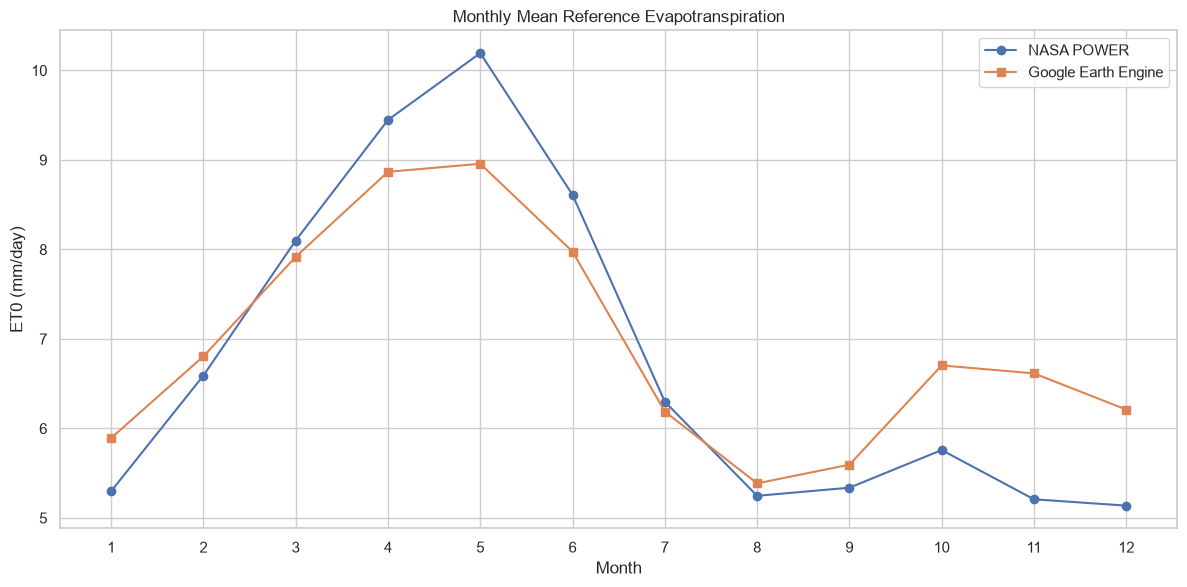

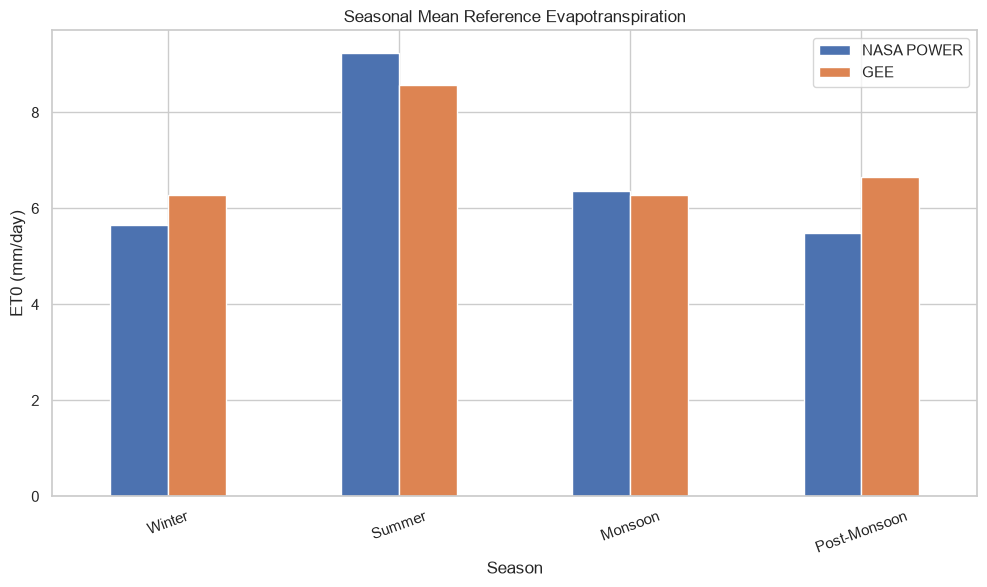

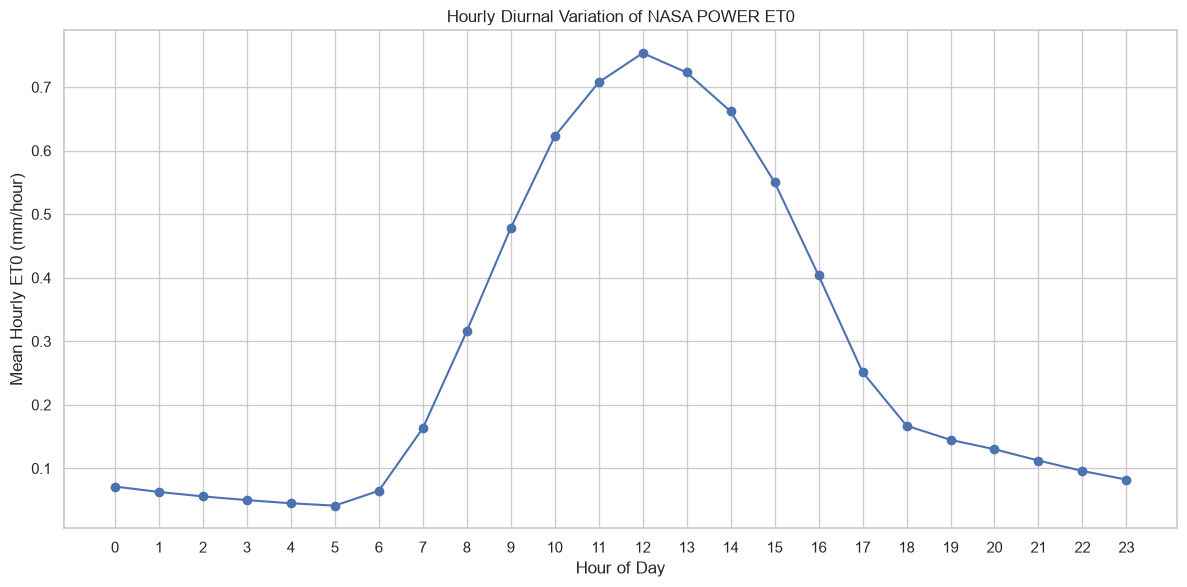

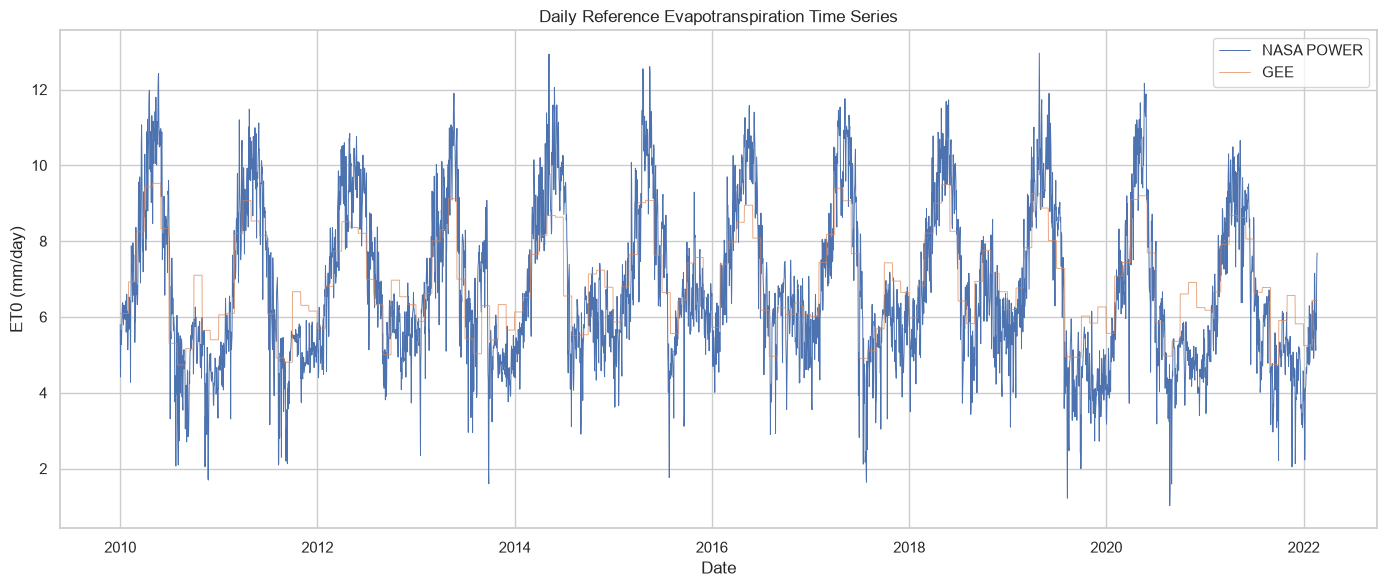

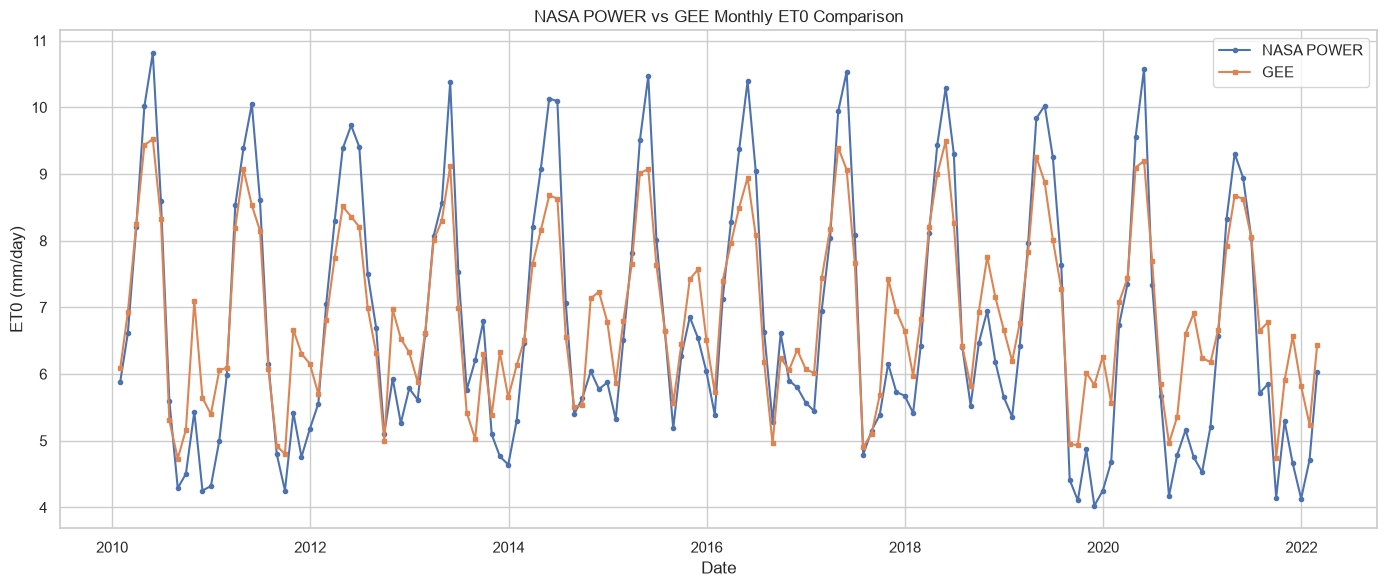

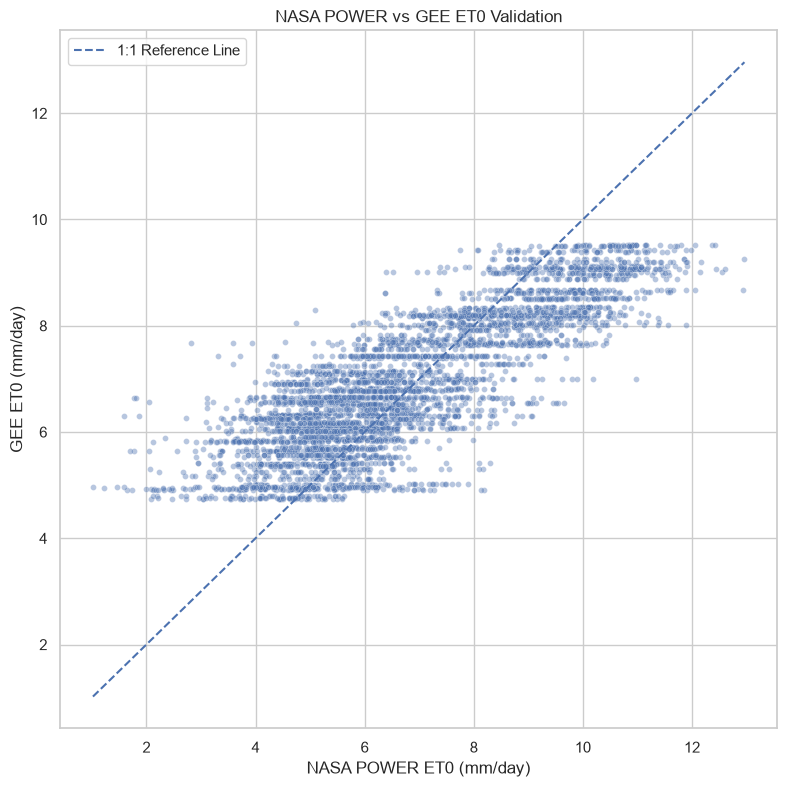


KUTCH ET0 ANALYSIS COMPLETED
Statistical metrics saved.
Six research graphs generated.
Results saved in: c:\Users\itsab\OneDrive\Desktop\Kutch-ET0-NASA-POWER-GEE-Analysis\results


In [21]:
# ============================================================
# KUTCH ET0 ANALYSIS
# Statistical Validation + Research Visualizations
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# ------------------------------------------------------------
# 1. Prepare validation data
# ------------------------------------------------------------

validation = matched.copy()

validation["date_only"] = pd.to_datetime(validation["date_only"])

validation = validation.replace([np.inf, -np.inf], np.nan)

validation = validation.dropna(
    subset=["NASA_ET0", "GEE_ET0"]
).copy()

observed = validation["NASA_ET0"]
predicted = validation["GEE_ET0"]

# ------------------------------------------------------------
# 2. Calculate statistical metrics
# ------------------------------------------------------------

r2 = r2_score(observed, predicted)

rmse = np.sqrt(mean_squared_error(observed, predicted))

mae = mean_absolute_error(observed, predicted)

mbe = np.mean(predicted - observed)

metrics = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE", "MBE"],
    "Calculated Value": [r2, rmse, mae, mbe],
    "Paper Reported Value": [0.6312, 1.2692, 1.0238, -0.1607]
})

metrics["Difference"] = (
    metrics["Calculated Value"] -
    metrics["Paper Reported Value"]
)

print("STATISTICAL VALIDATION RESULTS")
display(metrics.round(4))

print("Total Matched Observations:", len(validation))

# ------------------------------------------------------------
# 3. Prepare monthly and seasonal statistics
# ------------------------------------------------------------

validation["month"] = validation["date_only"].dt.month

validation["season"] = validation["month"].map({
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Summer",
    4: "Summer",
    5: "Summer",
    6: "Monsoon",
    7: "Monsoon",
    8: "Monsoon",
    9: "Monsoon",
    10: "Post-Monsoon",
    11: "Post-Monsoon"
})

monthly = validation.groupby("month").agg(
    NASA_ET0=("NASA_ET0", "mean"),
    GEE_ET0=("GEE_ET0", "mean")
).reset_index()

seasonal = validation.groupby("season").agg(
    NASA_ET0=("NASA_ET0", "mean"),
    GEE_ET0=("GEE_ET0", "mean")
).reindex([
    "Winter",
    "Summer",
    "Monsoon",
    "Post-Monsoon"
]).reset_index()

# ------------------------------------------------------------
# 4. Prepare diurnal statistics
# ------------------------------------------------------------

nasa_diurnal = nasa.copy()

nasa_diurnal["date_only"] = pd.to_datetime(
    nasa_diurnal["datetime"]
).dt.date

diurnal = nasa_diurnal.groupby("HR")["ET0"].mean()

# ------------------------------------------------------------
# 5. Prepare monthly time series
# ------------------------------------------------------------

time_series = validation.set_index("date_only").resample("ME").agg({
    "NASA_ET0": "mean",
    "GEE_ET0": "mean"
}).dropna()

# ------------------------------------------------------------
# 6. Publication graph settings
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

# ------------------------------------------------------------
# GRAPH 1: Monthly ET0 Variation
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    monthly["month"],
    monthly["NASA_ET0"],
    marker="o",
    label="NASA POWER"
)

ax.plot(
    monthly["month"],
    monthly["GEE_ET0"],
    marker="s",
    label="Google Earth Engine"
)

ax.set_title("Monthly Mean Reference Evapotranspiration")
ax.set_xlabel("Month")
ax.set_ylabel("ET0 (mm/day)")
ax.set_xticks(range(1, 13))
ax.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_monthly_et0.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# GRAPH 2: Seasonal ET0 Variation
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

seasonal.plot(
    x="season",
    y=["NASA_ET0", "GEE_ET0"],
    kind="bar",
    ax=ax
)

ax.set_title("Seasonal Mean Reference Evapotranspiration")
ax.set_xlabel("Season")
ax.set_ylabel("ET0 (mm/day)")
ax.legend(["NASA POWER", "GEE"])

plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_seasonal_et0.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# GRAPH 3: Diurnal ET0 Variation
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    diurnal.index,
    diurnal.values,
    marker="o"
)

ax.set_title("Hourly Diurnal Variation of NASA POWER ET0")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Mean Hourly ET0 (mm/hour)")
ax.set_xticks(range(0, 24))
ax.grid(True)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "03_diurnal_et0.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# GRAPH 4: Daily ET0 Time Series
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    validation["date_only"],
    validation["NASA_ET0"],
    label="NASA POWER",
    linewidth=0.7
)

ax.plot(
    validation["date_only"],
    validation["GEE_ET0"],
    label="GEE",
    linewidth=0.7,
    alpha=0.7
)

ax.set_title("Daily Reference Evapotranspiration Time Series")
ax.set_xlabel("Date")
ax.set_ylabel("ET0 (mm/day)")
ax.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_daily_timeseries.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# GRAPH 5: NASA POWER vs GEE Monthly Comparison
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    time_series.index,
    time_series["NASA_ET0"],
    label="NASA POWER",
    marker="o",
    markersize=3
)

ax.plot(
    time_series.index,
    time_series["GEE_ET0"],
    label="GEE",
    marker="s",
    markersize=3
)

ax.set_title("NASA POWER vs GEE Monthly ET0 Comparison")
ax.set_xlabel("Date")
ax.set_ylabel("ET0 (mm/day)")
ax.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "05_nasa_gee_comparison.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# GRAPH 6: Statistical Validation Scatter Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 8))

sns.scatterplot(
    x=observed,
    y=predicted,
    alpha=0.4,
    s=18,
    ax=ax
)

minimum = min(observed.min(), predicted.min())
maximum = max(observed.max(), predicted.max())

ax.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="1:1 Reference Line"
)

ax.set_title("NASA POWER vs GEE ET0 Validation")
ax.set_xlabel("NASA POWER ET0 (mm/day)")
ax.set_ylabel("GEE ET0 (mm/day)")
ax.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "06_validation_scatter.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 7. Save Results
# ------------------------------------------------------------

metrics.to_csv(
    RESULTS_DIR / "statistical_metrics.csv",
    index=False
)

validation.to_csv(
    RESULTS_DIR / "matched_validation_data.csv",
    index=False
)

monthly.to_csv(
    RESULTS_DIR / "monthly_et0_statistics.csv",
    index=False
)

seasonal.to_csv(
    RESULTS_DIR / "seasonal_et0_statistics.csv",
    index=False
)

print("\n========================================")
print("KUTCH ET0 ANALYSIS COMPLETED")
print("========================================")

print("Statistical metrics saved.")
print("Six research graphs generated.")
print("Results saved in:", RESULTS_DIR)